In [2]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_percentage_error

import seaborn as sns

import matplotlib.pyplot as plt

import numpy as np

# from catboost import CatBoostRegressor
import xgboost as xgb

import plotly.express as px
from plotly.subplots import make_subplots
import plotly.graph_objects as go
from itertools import cycle
import matplotlib.colors as mcolors
import matplotlib.patches as mpatches

# from genai_evaluation import multivariate_ecdf, ks_statistic
from scipy import stats

In [3]:
ENCODING_FILENAME = "./__encoding__solutions.csv"
df = pd.read_csv(ENCODING_FILENAME)
print("Dataframe shape:", df.shape)
print(df.columns)
df.head()

FileNotFoundError: [Errno 2] No such file or directory: './__encoding__solutions.csv'

In [173]:
# Plots the distribution of the quality-attribute objectives as boxplots
def make_boxplots(df, figsize=(400,1000), title='', yaxis_range=None):
  """Plots the distribution of quality-attribute objectives as boxplots.

  This function creates boxplots to visualize the distribution of data in a
  Pandas DataFrame. It uses Plotly to generate interactive boxplots for
  each column in the DataFrame. You can customize the figure size and title.

  Args:
      df: The Pandas DataFrame containing the data to be plotted.
      figsize: A tuple specifying the width and height of the figure
               (default: (400, 1000)).
      title: The title of the plot (default: '').
      yaxis_range: A list or tuple of (min, max) values to define the range
                   of the y-axis for each subplot. If None, the minimum
                   and maximum values of the column are used (default: None).
  """

  fig = make_subplots(rows=1, cols=len(df.columns))
  y_range = None
  for idx,c in enumerate(df.columns):
    if yaxis_range is not None:
      y_range = yaxis_range[idx]
    fig.add_trace(
      go.Box(y=df[c], boxpoints='all', name=c),
      row=1, col=idx+1
    )

  fig.update_layout(height=figsize[0], width=figsize[1], title_text=title)
  fig.show()
  plt.tight_layout()

In [174]:
x_cols = [col for col in df.columns if not col.startswith("y")]
y_cols = [col for col in df.columns if col.startswith("y")]

X = df[x_cols].drop(columns=["solID", "population_number"], axis=1)
y = df[["solID"] + y_cols].drop(columns=["solID"], axis=1)
print("objectives:", len(y_cols))

objectives: 10


In [175]:
# Show distribution of quality-attribute objectives for ST+
scaler = StandardScaler() # Objectives are first standardized using Z-score method
scaled_df = pd.DataFrame(scaler.fit_transform(df[y_cols]), columns=y_cols)
make_boxplots(scaled_df, title='Objectives (Z-scaled)', figsize=(1000, 2500))
plt.show()

<Figure size 640x480 with 0 Axes>

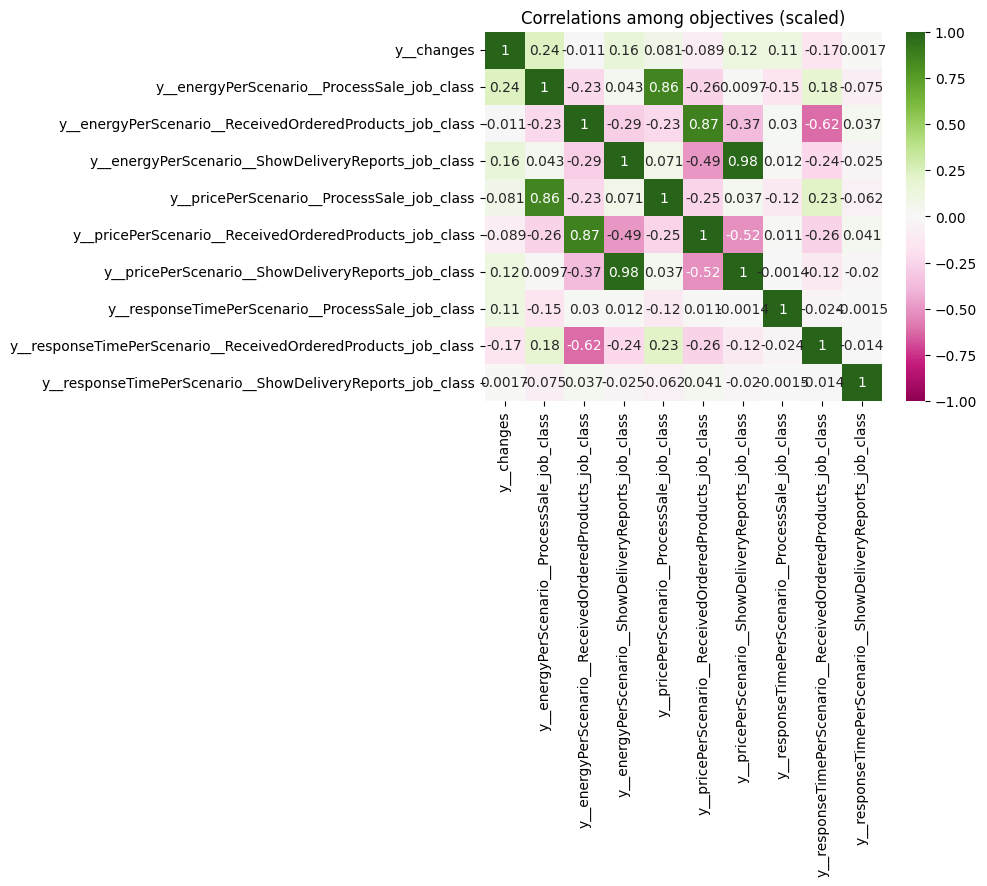

In [176]:
# Check correlation among objectives
sns.heatmap(scaled_df.corr(), annot=True, vmin=-1, vmax=1, cmap="PiYG") # Divergent palette
plt.title('Correlations among objectives (scaled)')
plt.show()

In [177]:
XGBOOST_DEFAULT_PARAMS = {
        'objective': 'reg:squarederror',
        'eval_metric': 'rmse',
        'n_estimators': 1000,
        'learning_rate': 0.1,
        'random_state': 42,
        # 'multi_strategy': 'one_output_per_tree'
    }

def train_xgboost_per_target(X, y, test_size=0.2, stratify=None, previous_model=None):

    if stratify is not None:
        print(f"\tapplying stratification on level!")

    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=test_size, stratify=stratify, random_state=42)

    model = xgb.XGBRegressor(**XGBOOST_DEFAULT_PARAMS)
    model.fit(X_train, y_train, xgb_model=previous_model)
    y_pred = model.predict(X_test)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse) 
    r2 = r2_score(y_test, y_pred)
    mape = mean_absolute_percentage_error(y_test, y_pred)

    print(f"\tTest metrics: R2={r2} -- RMSE={rmse} -- MAPE={(mape * 100):.2f}% ")
    return model, r2, rmse, mape

In [178]:
possible_objectives = [col for col in df.columns if col.startswith('y__')]
possible_objectives

['y__changes',
 'y__energyPerScenario__ProcessSale_job_class',
 'y__energyPerScenario__ReceivedOrderedProducts_job_class',
 'y__energyPerScenario__ShowDeliveryReports_job_class',
 'y__pricePerScenario__ProcessSale_job_class',
 'y__pricePerScenario__ReceivedOrderedProducts_job_class',
 'y__pricePerScenario__ShowDeliveryReports_job_class',
 'y__responseTimePerScenario__ProcessSale_job_class',
 'y__responseTimePerScenario__ReceivedOrderedProducts_job_class',
 'y__responseTimePerScenario__ShowDeliveryReports_job_class']

In [179]:
good_objectives = []
bad_objectives = []
for obj in y_cols:
    print(f"Training model for objective: {obj}")
    previous_model = None
    model, r2, rmse, mape = train_xgboost_per_target(X, y[obj], test_size=0.3, stratify=df["population_number"])
    if r2 >= 0.7 and mape <= 0.5:
        good_objectives.append(obj)
    else:
        print(f"\tObjective {obj} is discarded")
        bad_objectives.append(obj)
print("Good objectives:", len(good_objectives), good_objectives)

Training model for objective: y__changes
	applying stratification on level!
	Test metrics: R2=0.8725209096218001 -- RMSE=0.7763617869117746 -- MAPE=3.87% 
Training model for objective: y__energyPerScenario__ProcessSale_job_class
	applying stratification on level!
	Test metrics: R2=0.8677466118894912 -- RMSE=10.76248934720542 -- MAPE=3.32% 
Training model for objective: y__energyPerScenario__ReceivedOrderedProducts_job_class
	applying stratification on level!
	Test metrics: R2=0.8429461668129616 -- RMSE=12.00784625513725 -- MAPE=5.82% 
Training model for objective: y__energyPerScenario__ShowDeliveryReports_job_class
	applying stratification on level!
	Test metrics: R2=0.8366568423695643 -- RMSE=8.778298179314115 -- MAPE=40.47% 
Training model for objective: y__pricePerScenario__ProcessSale_job_class
	applying stratification on level!
	Test metrics: R2=0.8692687894956544 -- RMSE=0.11493554565858093 -- MAPE=2.40% 
Training model for objective: y__pricePerScenario__ReceivedOrderedProducts_

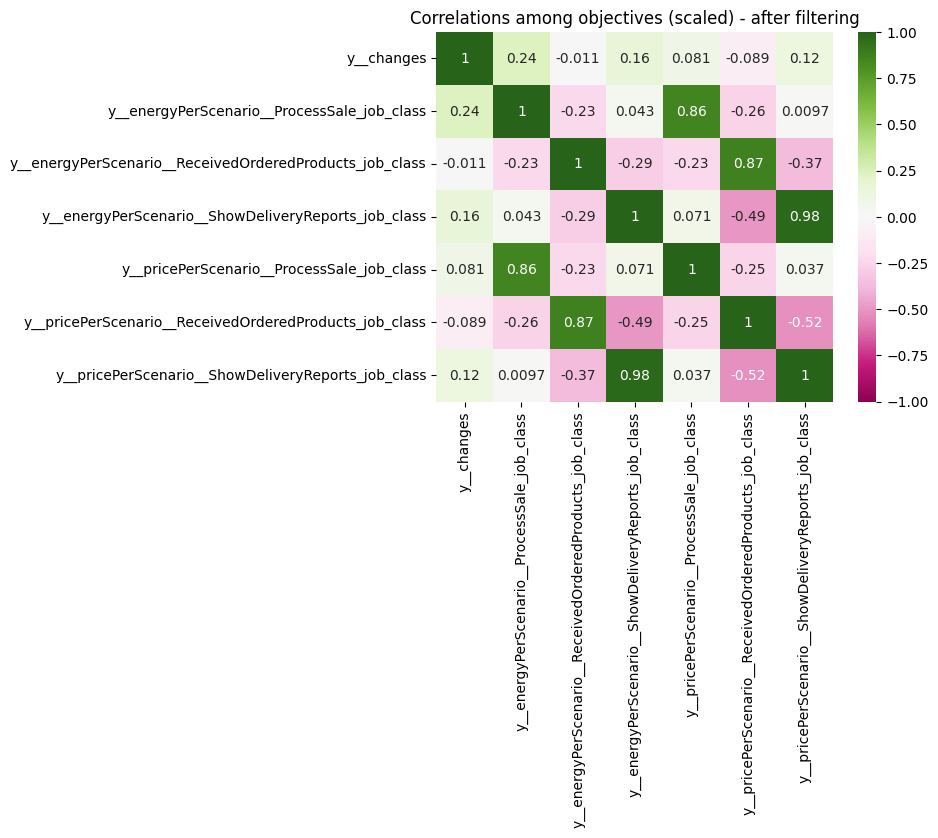

In [180]:
# Check correlation among objectives
sns.heatmap(scaled_df[good_objectives].corr(), annot=True, vmin=-1, vmax=1, cmap="PiYG") # Divergent palette
plt.title('Correlations among objectives (scaled) - after filtering')
plt.show()

In [181]:
y_filtered = df[good_objectives]
X_train, X_test, y_train, y_test = train_test_split(X, y_filtered, test_size=0.3, stratify=df["population_number"], random_state=42)

global_model = xgb.XGBRegressor(**XGBOOST_DEFAULT_PARAMS, multi_strategy="one_output_per_tree") #, early_stopping_rounds=10) #"one_output_per_tree") "multi_output_tree")
# global_model.fit(X_train, y_train)
global_model.fit(X_train, y_train, eval_set=[(X_test, y_test)], verbose=False)
# print("Best iteration:", global_model.best_iteration)

y_pred = global_model.predict(X_test)
mse = mean_squared_error(y_test.to_numpy(), y_pred, multioutput='uniform_average')
rmse = np.sqrt(mse) 
r2 = r2_score(y_test.to_numpy(), y_pred, multioutput='variance_weighted')
mape = mean_absolute_percentage_error(y_test.to_numpy(), y_pred, multioutput='uniform_average')

print(f"Training XGBoost model - Test error R2={r2} and RMSE={rmse} and MAPE={(mape * 100):.2f}%")

# final_model = xgb.XGBRegressor(**XGBOOST_DEFAULT_PARAMS, n_estimators=global_model.best_iteration, multi_strategy="one_output_per_tree", early_stopping_rounds=10) #"one_output_per_tree") "multi_output_tree")
# final_model.fit(X_train, y_train, eval_set=[(X_test, y_test)], verbose=False)

# y_pred = final_model.predict(X_test)
# mse = mean_squared_error(y_test.to_numpy(), y_pred, multioutput='uniform_average')
# rmse = np.sqrt(mse) 
# r2 = r2_score(y_test.to_numpy(), y_pred, multioutput='variance_weighted')
# mape = mean_absolute_percentage_error(y_test.to_numpy(), y_pred, multioutput='uniform_average')

# print(f"Training XGBoost model (early stopping, best iteration) - Test error R2={r2} and RMSE={rmse} and MAPE={(mape * 100):.2f}%")



Training XGBoost model - Test error R2=0.8529620071016932 and RMSE=6.906289568362936 and MAPE=14.61%


In [182]:
df["population_number"].value_counts()

population_number
1      12
33     12
35     12
36     12
37     12
       ..
16     12
160    12
161    12
162    12
99     12
Name: count, Length: 196, dtype: int64

In [183]:
def compute_multivariate_ks(validation_data, pred_data, n_nodes=2000, random_seed=2, verbose=False):
  """Calculates the multivariate Kolmogorov-Smirnov (KS) statistic between two datasets.

  This function compares the empirical cumulative distribution functions (ECDFs) of
  `validation_data` and `pred_data` to assess the similarity of their distributions.
  It uses a grid-based approach with `n_nodes` to approximate the ECDFs.

  Args:
      validation_data (np.ndarray): The validation dataset.
      pred_data (np.ndarray): The predicted data.
      n_nodes (int, optional): Number of grid nodes for ECDF approximation. Defaults to 2000.
      random_seed (int, optional): Random seed for reproducibility. Defaults to 2.
      verbose (bool, optional): Whether to print progress information. Defaults to False.

  Returns:
      float: The multivariate KS statistic, representing the maximum separation
             between the ECDFs of the two datasets. A value closer to 0 indicates
             a better fit between the distributions.
  """

  # Calculate ECDFs
  _, ecdf_val, ecdf_pred = multivariate_ecdf(validation_data, pred_data, n_nodes = n_nodes,
                                               verbose = verbose, random_seed=random_seed)
  # Calculates the maximum separation (distance) between the ECDFs and yields a result ranging
  # from 0 (indicating the best fit) and 1 (indicating the worst fit).
  ks_stat = ks_statistic(ecdf_val, ecdf_pred)
  return ks_stat

def compute_univariate_ks(validation_data, pred_data, targets=None):
  """Calculates the univariate Kolmogorov-Smirnov (KS) statistic for each target variable.

  This function compares the distributions of the validation data and the predicted data
  for each target variable using the two-sample KS test. It returns a list of tuples,
  where each tuple contains the KS statistic and p-value for a target variable.

  Args:
      validation_data (np.ndarray): The validation dataset.
      pred_data (np.ndarray): The predicted data.
      targets (list or None, optional): A list of target variable names.
                                        If None, the results will not include target names.
                                        Defaults to None.

  Returns:
      list: A list of tuples, where each tuple contains:
            - If `targets` is provided: (target_name, ks_statistic, p_value)
            - If `targets` is None: (ks_statistic, p_value)
  """

  ks_stats = []
  for x in range(0,validation_data.shape[1]):
    sample1 = validation_data[:,x]
    sample2 = pred_data[:,x]
    ks = stats.ks_2samp(sample1, sample2)
    if targets is None:
      ks_stats.append((ks.statistic,ks.pvalue))
    else:
      ks_stats.append((targets[x],ks.statistic,ks.pvalue))
  return ks_stats

In [184]:
baseline = df[df["population_number"]==1][x_cols].drop("solID", axis=1)
newbatch = df[df["population_number"]==5][x_cols].drop("solID", axis=1)

In [185]:
X_baseline = df[df["population_number"]==2][x_cols].drop("solID", axis=1)
X_newbatch = df[df["population_number"]==56][x_cols].drop("solID", axis=1)

# result = compute_univariate_ks(newbatch.values, baseline.values, targets=newbatch.columns)
result = compute_multivariate_ks(X_baseline, X_newbatch, n_nodes=100)
result

0.5

In [186]:
from alibi_detect.cd import KSDrift

X_baseline = df[df["population_number"]==2][x_cols].drop("solID", axis=1)
X_newbatch = df[df["population_number"]==56][x_cols].drop("solID", axis=1)

x_ref = X_baseline.values
cd = KSDrift(x_ref, p_val=0.05)

x = X_newbatch.values
preds = cd.predict(x, drift_type='batch', return_p_val=True, return_distance=True)
print("Is drift?", preds['data']['is_drift'])


Is drift? 1


In [187]:
preds

{'data': {'is_drift': 1,
  'distance': array([0.33333334, 0.6666667 , 0.25      , 0.33333334, 0.6666667 ,
         0.16666667, 0.25      , 0.16666667, 0.33333334, 0.16666667,
         0.25      , 0.16666667, 0.16666667, 0.16666667, 0.        ,
         0.        , 0.16666667, 0.33333334, 0.16666667, 0.41666666,
         0.16666667, 0.08333334, 0.5833333 , 0.16666667, 0.08333334,
         0.33333334, 0.5       , 0.25      , 0.41666666, 0.16666667,
         0.        , 0.16666667, 0.        , 0.16666667, 0.16666667,
         0.16666667, 0.25      , 0.08333334, 0.16666667, 0.08333334,
         0.16666667, 0.08333334, 0.08333334, 0.33333334, 0.5       ,
         0.08333334, 0.08333334, 0.5       , 0.08333334, 0.16666667,
         0.25      , 0.25      , 0.25      , 0.16666667, 0.08333334,
         0.16666667, 0.25      , 0.33333334, 1.        ], dtype=float32),
  'p_val': array([0.42343965, 0.00377229, 0.76948303, 0.42343965, 0.00377229,
         0.9845679 , 0.76948303, 0.9845679 , 0.42343

---

In [211]:
# encoding_ga_refactor.py
from __future__ import annotations
import json
import itertools
import re
from pathlib import Path
from typing import Dict, List, Union, Optional

import pandas as pd

class EasierEncoder:

    ACTIONS = ["mcnn", "moc", "moncnn", "clone"]  # fixed vocabulary of actions
    BIGRAMS = [f"{a1}_{a2}" for a1, a2 in itertools.product(ACTIONS, repeat=2)]

    # --- Node family/size vocab (fixed at time zero) ---
    FAMILY_PREFIXES = {"t2", "t3", "m5", "m5ad", "m6i", "c5", "c6i", "r5", "r6i", "d2"}
    SIZE_CLASSES = {
        "nano", "micro", "small", "medium", "large",
        "xlarge", "2xlarge", "4xlarge", "8xlarge",
        "12xlarge", "16xlarge", "24xlarge", "32xlarge"
    }
    FAM_OTHER = "OTHER"
    SIZE_OTHER = "OTHER"

    # Matches pieces like 'm6i.xlarge', 'd2.2xlarge' anywhere in a token
    _family_size_re = re.compile(
        r"([a-z]+\d+[a-z]*)\.(\d*x?large|nano|micro|small|medium|large)", re.I
    )

    @staticmethod
    def _pos_feature_names(max_len: int = 4) -> List[str]:
        return [f"pos{p}_{a}" for p in range(1, max_len + 1) for a in EasierEncoder.ACTIONS]

    @staticmethod
    def _all_family_prefixes() -> List[str]:
        return sorted(EasierEncoder.FAMILY_PREFIXES | {EasierEncoder.FAM_OTHER})

    @staticmethod
    def _all_size_classes() -> List[str]:
        return sorted(EasierEncoder.SIZE_CLASSES | {EasierEncoder.SIZE_OTHER})

    @staticmethod
    def _node_feature_names() -> List[str]:
        fams = EasierEncoder._all_family_prefixes()
        sizes = EasierEncoder._all_size_classes()
        names: List[str] = []
        # global family counts
        names += [f"count_family_{fam}" for fam in fams]
        # per-action-to-family counts (only actions that place on a node)
        for a in ("mcnn", "moncnn", "clone"):
            names += [f"count_{a}_to_family_{fam}" for fam in fams]
        # size counts
        names += [f"count_size_{s}" for s in sizes]
        # diversity
        names += ["uniq_families_used", "uniq_sizes_used"]
        return names

    @staticmethod
    def extract_family_size(token: str) -> tuple[str, str]:
        """
        Find '<family>.<size>' in a token, normalize into fixed vocab with OTHER fallback.
        Examples: 'm6i.xlarge', 'd2.2xlarge', possibly inside 'New-Node_m6i.xlarge_xyz'
        """
        if not token:
            return (EasierEncoder.FAM_OTHER, EasierEncoder.SIZE_OTHER)
        m = EasierEncoder._family_size_re.search(token)
        if not m:
            # try substrings split by '_' if embedded
            for part in token.split("_"):
                m = EasierEncoder._family_size_re.search(part)
                if m:
                    break
        if m:
            fam = m.group(1).lower()
            size = m.group(2).lower()
            fam_norm = fam if fam in EasierEncoder.FAMILY_PREFIXES else EasierEncoder.FAM_OTHER
            size_norm = size if size in EasierEncoder.SIZE_CLASSES else EasierEncoder.SIZE_OTHER
            return (fam_norm, size_norm)
        return (EasierEncoder.FAM_OTHER, EasierEncoder.SIZE_OTHER)

    @staticmethod
    def add_node_family_features(encoding: Dict, refactoring_steps: List[Dict]) -> None:
        """
        Mutates `encoding` in place, adding:
        - count_family_{fam}, count_size_{size}
        - count_{action}_to_family_{fam} for actions that place on a node (mcnn/moncnn/clone)
        - uniq_families_used, uniq_sizes_used
        """
        # Initialize all node-related columns for stability
        for fam in EasierEncoder._all_family_prefixes():
            encoding[f"count_family_{fam}"] = 0
            encoding[f"count_mcnn_to_family_{fam}"] = 0
            encoding[f"count_moncnn_to_family_{fam}"] = 0
            encoding[f"count_clone_to_family_{fam}"] = 0
        for size in EasierEncoder._all_size_classes():
            encoding[f"count_size_{size}"] = 0
        encoding["uniq_families_used"] = 0
        encoding["uniq_sizes_used"] = 0

        fam_seen, size_seen = set(), set()

        for step in refactoring_steps:
            name = (step.get("name") or "").strip()
            # Determine where the node info lives
            node_token = ""
            if name == "mcnn":
                node_token = step.get("to", "")
            elif name == "moncnn":
                node_token = step.get("where", "")
            elif name == "clone":
                node_token = step.get("to", "")
            else:
                # moc: no new node destination; skip
                continue

            fam, size = EasierEncoder.extract_family_size(node_token)

            # global counts
            encoding[f"count_family_{fam}"] += 1
            encoding[f"count_size_{size}"] += 1
            fam_seen.add(fam)
            size_seen.add(size)

            # per-action cross
            if name in ("mcnn", "moncnn", "clone"):
                encoding[f"count_{name}_to_family_{fam}"] += 1

        encoding["uniq_families_used"] = len(fam_seen)
        encoding["uniq_sizes_used"] = len(size_seen)


    def encode_solution(self,
        solution: Dict,
        include_bigrams: bool = True,
        include_positional: bool = True,
        positional_len: int = 4,
    ) -> Dict:
        """
        Encode a single solution into a fixed-size vector.

        Features:
        - count_*: unigram counts over ACTIONS
        - bigram_*: pair counts over ACTIONS x ACTIONS (if include_bigrams=True)
        - pos{k}_{action}: one-hot for action at position k (1..positional_len) (if include_positional=True)
        - num_new_nodes_created, num_new_components_created: derived from action semantics
        - node family/size features parsed from destination/where tokens
        - sequence_len, solID
        - y__<objective>: considered objectives as targets/labels (prefixed)

        Assumptions:
        - mcnn -> creates a new node
        - moncnn -> creates a new component + new node
        - clone -> creates a new node
        - moc -> moves operation to existing component (no new elements)
        """
        ref = solution.get("refactoring", []) or []
        actions = [step.get("name", "").strip() for step in ref]
        # considered = solution.get("consideredObjectives", {}) or {}
        considered = solution.get("objectives", {}) or {}

        feats: Dict[str, Union[int, float, str]] = {}

        # Base: IDs / metadata
        feats["solID"] = solution.get("solID", None)
        feats["sequence_len"] = len(actions)

        # Unigrams
        for a in EasierEncoder.ACTIONS:
            feats[f"count_{a}"] = 0
        for a in actions:
            if a in EasierEncoder.ACTIONS:
                feats[f"count_{a}"] += 1

        # Bigrams
        if include_bigrams:
            for b in EasierEncoder.BIGRAMS:
                feats[f"bigram_{b}"] = 0
            for a1, a2 in zip(actions, actions[1:]):
                if a1 in EasierEncoder.ACTIONS and a2 in EasierEncoder.ACTIONS:
                    feats[f"bigram_{a1}_{a2}"] += 1

        # Positional one-hots (fixed first N positions; missing remain 0)
        if include_positional:
            for name in EasierEncoder._pos_feature_names(positional_len):
                feats[name] = 0
            for idx, a in enumerate(actions[:positional_len], start=1):
                if a in EasierEncoder.ACTIONS:
                    feats[f"pos{idx}_{a}"] = 1

        # Creation counters (derived from action semantics)
        feats["num_new_components_created"] = feats["count_moncnn"]
        feats["num_new_nodes_created"] = (
            feats["count_mcnn"] + feats["count_moncnn"] + feats["count_clone"]
        )

        # --- Node family/size features from tokens like 'm6i.xlarge' / 'd2.2xlarge' ---
        EasierEncoder.add_node_family_features(feats, ref)

        # Targets (considered objectives)
        for k, v in considered.items():
            feats[f"y__{k}"] = v

        return feats


    def encode_population(self,
        population: Dict,
        include_bigrams: bool = True,
        include_positional: bool = True,
        positional_len: int = 4,
        save_csv: Optional[Union[str, Path]] = None,
        family_filter: bool = False,
    ) -> pd.DataFrame:
        """Encode all solutions in a population JSON to a DataFrame."""
        solutions = population.get("solutions", []) or []
        rows = [
            self.encode_solution(
                sol,
                include_bigrams=include_bigrams,
                include_positional=include_positional,
                positional_len=positional_len,
            )
            for sol in solutions
        ]
        df = pd.DataFrame(rows)

        # Order columns for readability (keep stable)
        col_order: List[str] = []
        col_order += ["solID", "sequence_len", "num_new_nodes_created", "num_new_components_created"]
        col_order += [f"count_{a}" for a in EasierEncoder.ACTIONS]
        if include_bigrams:
            col_order += [f"bigram_{b}" for b in EasierEncoder.BIGRAMS]
        if include_positional:
            col_order += EasierEncoder._pos_feature_names(positional_len)
        # node family/size block
        col_order += EasierEncoder._node_feature_names()

        # targets at the end
        target_cols = sorted([c for c in df.columns if c.startswith("y__")])

        # plus any columns not covered (safe fallback)
        remaining = [c for c in df.columns if c not in set(col_order + target_cols)]
        df = df[col_order + remaining + target_cols]

        if save_csv is not None:
            save_csv = Path(save_csv)
            save_csv.parent.mkdir(parents=True, exist_ok=True)
            df.to_csv(save_csv, index=False)

        if family_filter:
            encoding_df = df[[x for x in df.columns if 'family' in x]]
            return encoding_df
        
        return df


    def load_population(self, src: Union[str, Path, Dict]) -> Dict:
        """Load a population JSON from a dict, string path, or raw JSON string."""
        if isinstance(src, dict):
            return src
        p = Path(src)
        if p.exists():
            return json.loads(Path(p).read_text(encoding="utf-8"))
        # if not a file, try to parse as raw JSON string
        return json.loads(str(src))

In [ ]:
class EasierSurrogate:
    
    XGBOOST_DEFAULT_PARAMS = {
        'objective': 'reg:squarederror',
        'eval_metric': 'rmse',
        'n_estimators': 1000,
        'learning_rate': 0.1,
        'random_state': 42,
        # 'multi_strategy': 'one_output_per_tree' # 'multi_output_tree' # 'one_output_per_tree'
    }
    
    def __init__(self, objectives):
        self.objectives = objectives
        self.reset()

    def reset(self):
        self.model = {obj:None for obj in self.objectives}
        self.df = None
        self.features = None
    
    @staticmethod
    def get_data(df):
        x_cols = [col for col in df.columns if not col.startswith("y")]
        y_cols = [col for col in df.columns if col.startswith("y")]

        X = df[x_cols].drop(columns=["solID", "population_number"], axis=1)
        y = df[["solID"] + y_cols].drop(columns=["solID"], axis=1)
        print(X.shape, "objectives:", len(y_cols))

        return X, y
    
    @staticmethod
    def train_xgboost_per_target(X, y, test_size=None, stratify=None, strategy='one_output_per_tree', previous_model=None):

        if test_size is not None:
            X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=test_size, stratify=stratify, random_state=42)
            print(test_size, X_train.shape, X_test.shape)
        else:
            X_train, y_train = X, y
            X_test, y_test = None, None
        
        model = xgb.XGBRegressor(**EasierSurrogate.XGBOOST_DEFAULT_PARAMS, multi_strategy=strategy)
        model.fit(X_train, y_train, xgb_model=previous_model)
        
        return model, X_test, y_test
    
    @staticmethod
    def validate_xgboost_per_target(model, X_test, y_test):
        y_pred = model.predict(X_test)
        mse = mean_squared_error(y_test, y_pred)
        rmse = np.sqrt(mse) 
        r2 = r2_score(y_test, y_pred)
        mape = mean_absolute_percentage_error(y_test, y_pred)

        # print(f"\tTest metrics: R2={r2} -- RMSE={rmse} -- MAPE={(mape * 100):.2f}% ")
        return r2, rmse, mape
    
    @staticmethod
    def encode_as_dataframe(batch_dict, population_id):
        
        encoder = EasierEncoder()
        population_df = encoder.encode_population(
                batch_dict,
                include_bigrams=True,
                include_positional=True,
                positional_len=4,
                # save_csv=args.out,
            )
        population_df["population_number"] = population_id
        return population_df
    
    # This method should be called externally
    def encode_and_retain(self, batch_dict, population_id, accumulate=False):

        population_df = EasierSurrogate.encode_as_dataframe(batch_dict, population_id)        
        self.retain(population_df, accumulate=accumulate)
    
    def retain(self, batch_df, accumulate=False):
        if not accumulate:
            self.df = batch_df  
        elif self.df is None:
            self.df = batch_df
        else:
            result = pd.concat([self.df, batch_df], ignore_index=True) 
            self.df = result
        print("Retain:", self.df.shape)

    # This method should be called externally
    def train(self, incremental_learning=False, test_size=0.25, strategy='one_output_per_tree'):

        X, y = EasierSurrogate.get_data(self.df)
        # print(X.shape, y.shape)
        self.features = X.columns

        for obj in self.objectives:
            print(f"Training model for objective: {obj}")
            previous_model = self.model[obj] if incremental_learning else None
            model, X_test, y_test = EasierSurrogate.train_xgboost_per_target(
                            X, y[obj], 
                            test_size=test_size, 
                            stratify=self.df["population_number"],
                            previous_model=previous_model,
                            strategy=strategy
                        )
            if (X_test is not None) and (y_test is not None):
                r2, rmse, mape = EasierSurrogate.validate_xgboost_per_target(model, X_test, y_test)
                print(f"\tTest metrics: R2={r2} -- RMSE={rmse} -- MAPE={(mape * 100):.2f}% ")
            else:
                print("Skipping validation")
            self.model[obj] = model
    
    # This method should be called externally
    def encode_and_active_learning(self, batch_dict, population_id, strategy='one_output_per_tree'):
                
        population_df = EasierSurrogate.encode_as_dataframe(batch_dict, population_id)
        return self.active_learning(population_df, strategy=strategy)
            
    def active_learning(self, batch_df, strategy='one_output_per_tree'):
        # sample_population = batch_df.sample(frac=sampling_factor, random_state=random_state)
        # Select only those raws with values (not NaN) in their objectives
        sample_population = batch_df[batch_df[self.objectives].notna().all(axis=1)]

        self.retain(sample_population, accumulate=True)
        self.train(incremental_learning=True, test_size=None, strategy=strategy)

        # Get the remaining rows from population3 that are not in sample
        remaining_indices = batch_df.index.difference(sample_population.index)
        remaining_population = batch_df.loc[remaining_indices]

        return self.predict(remaining_population[surrogate.features])
    
    # This method should be called externally
    def encode_and_predict(self, batch_dict, population_id):

        population_df = EasierSurrogate.encode_as_dataframe(batch_dict, population_id)
        return self.predict(population_df)

    def predict(self, batch_df):
        predictions_df = pd.DataFrame()
        for obj in self.objectives:
            predictions_df[obj] = self.model[obj].predict(batch_df)
        
        return predictions_df
        

In [190]:
JSON_FILENAME = JSON_FILENAME = "./easier_pop_json/population__1.json"

encoder = EasierEncoder()

population = encoder.load_population(JSON_FILENAME)
# population

In [191]:
population_df = encoder.encode_population(
    population,
    include_bigrams=True,
    include_positional=True,
    positional_len=4,
    family_filter=True,
    # save_csv=args.out,
)
population_df["population_number"] = 0
population_df

,count_family_OTHER,count_family_c5,count_family_c6i,count_family_d2,count_family_m5,count_family_m5ad,count_family_m6i,count_family_r5,count_family_r6i,count_family_t2,...,count_clone_to_family_c6i,count_clone_to_family_d2,count_clone_to_family_m5,count_clone_to_family_m5ad,count_clone_to_family_m6i,count_clone_to_family_r5,count_clone_to_family_r6i,count_clone_to_family_t2,count_clone_to_family_t3,population_number
0,0,0,0,0,0,1,1,0,0,1,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,3,0,0,0,0,0,0,...,0,2,0,0,0,0,0,0,0,0
2,0,0,0,2,0,0,1,0,0,1,...,0,2,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,2,0,0,1,...,0,0,0,0,1,0,0,0,0,0
4,0,0,0,1,0,0,1,0,0,2,...,0,0,0,0,0,0,0,0,0,0
5,0,0,0,1,0,1,0,0,0,0,...,0,1,0,0,0,0,0,0,0,0
6,0,0,0,0,0,1,2,0,0,0,...,0,0,0,0,0,0,0,0,0,0
7,0,0,0,2,0,0,0,0,0,0,...,0,2,0,0,0,0,0,0,0,0
8,0,0,0,1,0,0,1,0,0,0,...,0,1,0,0,0,0,0,0,0,0
9,0,0,0,1,0,1,1,0,0,0,...,0,1,0,1,1,0,0,0,0,0


In [192]:
good_objectives

['y__changes',
 'y__energyPerScenario__ProcessSale_job_class',
 'y__energyPerScenario__ReceivedOrderedProducts_job_class',
 'y__energyPerScenario__ShowDeliveryReports_job_class',
 'y__pricePerScenario__ProcessSale_job_class',
 'y__pricePerScenario__ReceivedOrderedProducts_job_class',
 'y__pricePerScenario__ShowDeliveryReports_job_class']

In [193]:
bad_objectives

['y__responseTimePerScenario__ProcessSale_job_class',
 'y__responseTimePerScenario__ReceivedOrderedProducts_job_class',
 'y__responseTimePerScenario__ShowDeliveryReports_job_class']

In [220]:
# JSON_FILENAME = JSON_FILENAME = "./easier_pop_json/population__1.json"

def load_populations_to_dictionary(prefix, n):
    encoder = EasierEncoder()
     
    populations = dict()
    for idx in range(1,n+1):
        json_filename = prefix + '__' + str(idx) + '.json'
        population = encoder.load_population(json_filename)
        populations[json_filename] = population

    return populations

all_populations_dict = load_populations_to_dictionary(prefix="./easier_pop_json/population", n=196)
all_populations = list(all_populations_dict.values())


In [221]:
target_objectives = [
        'y__changes',
        'y__energy',
        'y__energyPerScenario__ProcessSale_job_class',
        'y__energyPerScenario__ReceivedOrderedProducts_job_class',
        'y__energyPerScenario__ShowDeliveryReports_job_class',
        'y__pas',
        'y__perfq',
        'y__power',
        'y__price',
        'y__pricePerScenario__ProcessSale_job_class',
        'y__pricePerScenario__ReceivedOrderedProducts_job_class',
        'y__pricePerScenario__ShowDeliveryReports_job_class',
        'y__reliability'
        'y__responseTimePerScenario__ProcessSale_job_class',
        'y__responseTimePerScenario__ReceivedOrderedProducts_job_class',
        'y__responseTimePerScenario__ShowDeliveryReports_job_class',
        'y__sysRespT'
    ]

In [227]:
print(surrogate.df.shape)
surrogate.df.to_csv("allpopulations_encoded.csv", index=False)
surrogate.df

(2352, 118)


,solID,sequence_len,num_new_nodes_created,num_new_components_created,count_mcnn,count_moc,count_moncnn,count_clone,bigram_mcnn_mcnn,bigram_mcnn_moc,...,y__price,y__pricePerScenario__ProcessSale_job_class,y__pricePerScenario__ReceivedOrderedProducts_job_class,y__pricePerScenario__ShowDeliveryReports_job_class,y__reliability,y__responseTimePerScenario__ProcessSale_job_class,y__responseTimePerScenario__ReceivedOrderedProducts_job_class,y__responseTimePerScenario__ShowDeliveryReports_job_class,y__sysRespT,population_number
0,1,4,3,2,1,1,2,0,0,0,...,3.7753,2.354001,1.343544,0.077756,0.595982,654.297211,5.257940e+00,1.393670e+00,6.609488e+02,1
1,6,4,3,0,1,1,0,2,0,0,...,4.2068,1.888328,0.759298,0.632773,-0.633613,879.086300,7.215290e+00,1.943830e+00,8.882454e+02,1
2,4,4,4,1,1,0,1,2,0,0,...,4.3336,1.890800,1.002988,0.513412,-0.113465,2457.197030,5.343720e+00,1.286230e+00,2.463827e+03,1
3,3,4,3,2,0,1,2,1,0,0,...,3.8704,1.645012,0.899860,1.198728,-0.074655,694.365453,7.106040e+00,1.801970e+00,7.032735e+02,1
4,11,4,4,4,0,0,4,0,0,0,...,4.6700,2.352360,1.318462,0.535977,-0.729991,654.157823,8.112870e+00,1.292220e+00,6.635629e+02,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2347,4249,4,3,0,1,1,0,2,0,0,...,3.5340,1.883218,0.733057,0.200924,-0.805236,885.801610,6.649690e+00,5.069490e+00,8.975208e+02,196
2348,4264,4,3,1,1,1,1,1,0,0,...,3.5340,1.885478,1.182466,0.212456,-0.616102,661.060117,7.588830e+00,5.234390e+00,6.738833e+02,196
2349,4152,4,3,1,1,1,1,1,0,0,...,3.5340,1.885478,1.182466,0.212456,-0.616102,661.060117,7.588830e+00,5.234390e+00,6.738833e+02,196
2350,4228,4,2,1,1,2,1,0,0,1,...,3.3121,1.423322,1.086977,0.675002,-0.066624,711.707580,5.177810e+00,1.627760e+00,7.185131e+02,196


In [208]:
all_populations[0]

{'solutions': [{'objectives': {'pas': 12.0,
    'energyPerScenario__ReceivedOrderedProducts_job_class': 117.50331585417408,
    'energyPerScenario__ProcessSale_job_class': 181.29055757310016,
    'reliability': 0.5959816821261689,
    'changes': 9.62,
    'responseTimePerScenario__ReceivedOrderedProducts_job_class': 5.25794,
    'responseTimePerScenario__ProcessSale_job_class': 654.297211,
    'perfq': -0.2590398251629023,
    'price': 3.7752999999999997,
    'pricePerScenario__ProcessSale_job_class': 2.354000833302175,
    'responseTimePerScenario__ShowDeliveryReports_job_class': 1.39367,
    'pricePerScenario__ReceivedOrderedProducts_job_class': 1.3435439624283543,
    'power': 311.6039496035,
    'sysRespT': 660.948821,
    'energyPerScenario__ShowDeliveryReports_job_class': 12.810174236033497,
    'energy': 1190.7642404809205,
    'pricePerScenario__ShowDeliveryReports_job_class': 0.07775615509721485},
   'consideredObjectives': {'energyPerScenario__ReceivedOrderedProducts_job_clas

In [212]:
# surrogate = EasierSurrogate(target_objectives)
# population_idx = all_populations[0]

# surrogate.encode_as_dataframe(population_idx, population_id=0)


,solID,sequence_len,num_new_nodes_created,num_new_components_created,count_mcnn,count_moc,count_moncnn,count_clone,bigram_mcnn_mcnn,bigram_mcnn_moc,...,y__price,y__pricePerScenario__ProcessSale_job_class,y__pricePerScenario__ReceivedOrderedProducts_job_class,y__pricePerScenario__ShowDeliveryReports_job_class,y__reliability,y__responseTimePerScenario__ProcessSale_job_class,y__responseTimePerScenario__ReceivedOrderedProducts_job_class,y__responseTimePerScenario__ShowDeliveryReports_job_class,y__sysRespT,population_number
0,1,4,3,2,1,1,2,0,0,0,...,3.7753,2.354001,1.343544,0.077756,0.595982,6.542972e+02,5.257940e+00,1.393670e+00,6.609488e+02,0
1,6,4,3,0,1,1,0,2,0,0,...,4.2068,1.888328,0.759298,0.632773,-0.633613,8.790863e+02,7.215290e+00,1.943830e+00,8.882454e+02,0
2,4,4,4,1,1,0,1,2,0,0,...,4.3336,1.890800,1.002988,0.513412,-0.113465,2.457197e+03,5.343720e+00,1.286230e+00,2.463827e+03,0
3,3,4,3,2,0,1,2,1,0,0,...,3.8704,1.645012,0.899860,1.198728,-0.074655,6.943655e+02,7.106040e+00,1.801970e+00,7.032735e+02,0
4,11,4,4,4,0,0,4,0,0,0,...,4.6700,2.352360,1.318462,0.535977,-0.729991,6.541578e+02,8.112870e+00,1.292220e+00,6.635629e+02,0
5,17,4,2,0,1,2,0,1,0,0,...,3.5280,1.872497,0.655078,0.537225,-0.569956,6.802268e+02,7.951120e+00,1.259460e+00,6.894374e+02,0
6,8,4,3,0,3,1,0,0,1,1,...,3.3184,1.085199,1.041155,0.475245,0.639130,1.137754e+37,5.187270e+00,1.264980e+00,1.137754e+37,0
7,28,4,2,0,0,2,0,2,0,0,...,3.7436,1.884082,0.419372,0.513746,-0.569956,6.720632e+02,2.324290e+01,2.021470e+00,6.973275e+02,0
8,25,4,2,0,1,2,0,1,0,0,...,3.4072,1.913898,0.372443,0.530860,-0.704327,2.617792e+03,1.748840e+01,1.254500e+00,2.636535e+03,0
9,13,4,3,0,0,1,0,3,0,0,...,3.6548,1.890800,0.754423,0.171975,-0.761426,8.583101e+02,1.305910e+06,1.305900e+06,2.612668e+06,0


In [224]:
# surrogate = EasierSurrogate(good_objectives)
surrogate = EasierSurrogate(target_objectives)

n_populations = 196
for idx in range(0,n_populations):
    population_idx = all_populations[idx]
    surrogate.encode_and_retain(population_idx, population_id=idx+1, accumulate=True)
print(surrogate.df.shape)
# surrogate.train()

# print('=='*10)
# population2 = all_populations[n_populations+1]
# surrogate.encode_and_retain(population2, population_id=n_populations+1)
# surrogate.train(incremental_learning=True)

Retain: (12, 118)
Retain: (24, 118)
Retain: (36, 118)
Retain: (48, 118)
Retain: (60, 118)
Retain: (72, 118)
Retain: (84, 118)
Retain: (96, 118)
Retain: (108, 118)
Retain: (120, 118)
Retain: (132, 118)
Retain: (144, 118)
Retain: (156, 118)
Retain: (168, 118)
Retain: (180, 118)
Retain: (192, 118)
Retain: (204, 118)
Retain: (216, 118)
Retain: (228, 118)
Retain: (240, 118)
Retain: (252, 118)
Retain: (264, 118)
Retain: (276, 118)
Retain: (288, 118)
Retain: (300, 118)
Retain: (312, 118)
Retain: (324, 118)
Retain: (336, 118)
Retain: (348, 118)
Retain: (360, 118)
Retain: (372, 118)
Retain: (384, 118)
Retain: (396, 118)
Retain: (408, 118)
Retain: (420, 118)
Retain: (432, 118)
Retain: (444, 118)
Retain: (456, 118)
Retain: (468, 118)
Retain: (480, 118)
Retain: (492, 118)
Retain: (504, 118)
Retain: (516, 118)
Retain: (528, 118)
Retain: (540, 118)
Retain: (552, 118)
Retain: (564, 118)
Retain: (576, 118)
Retain: (588, 118)
Retain: (600, 118)
Retain: (612, 118)
Retain: (624, 118)
Retain: (636, 118)
R

In [225]:
surrogate.df

,solID,sequence_len,num_new_nodes_created,num_new_components_created,count_mcnn,count_moc,count_moncnn,count_clone,bigram_mcnn_mcnn,bigram_mcnn_moc,...,y__price,y__pricePerScenario__ProcessSale_job_class,y__pricePerScenario__ReceivedOrderedProducts_job_class,y__pricePerScenario__ShowDeliveryReports_job_class,y__reliability,y__responseTimePerScenario__ProcessSale_job_class,y__responseTimePerScenario__ReceivedOrderedProducts_job_class,y__responseTimePerScenario__ShowDeliveryReports_job_class,y__sysRespT,population_number
0,1,4,3,2,1,1,2,0,0,0,...,3.7753,2.354001,1.343544,0.077756,0.595982,654.297211,5.257940e+00,1.393670e+00,6.609488e+02,1
1,6,4,3,0,1,1,0,2,0,0,...,4.2068,1.888328,0.759298,0.632773,-0.633613,879.086300,7.215290e+00,1.943830e+00,8.882454e+02,1
2,4,4,4,1,1,0,1,2,0,0,...,4.3336,1.890800,1.002988,0.513412,-0.113465,2457.197030,5.343720e+00,1.286230e+00,2.463827e+03,1
3,3,4,3,2,0,1,2,1,0,0,...,3.8704,1.645012,0.899860,1.198728,-0.074655,694.365453,7.106040e+00,1.801970e+00,7.032735e+02,1
4,11,4,4,4,0,0,4,0,0,0,...,4.6700,2.352360,1.318462,0.535977,-0.729991,654.157823,8.112870e+00,1.292220e+00,6.635629e+02,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2347,4249,4,3,0,1,1,0,2,0,0,...,3.5340,1.883218,0.733057,0.200924,-0.805236,885.801610,6.649690e+00,5.069490e+00,8.975208e+02,196
2348,4264,4,3,1,1,1,1,1,0,0,...,3.5340,1.885478,1.182466,0.212456,-0.616102,661.060117,7.588830e+00,5.234390e+00,6.738833e+02,196
2349,4152,4,3,1,1,1,1,1,0,0,...,3.5340,1.885478,1.182466,0.212456,-0.616102,661.060117,7.588830e+00,5.234390e+00,6.738833e+02,196
2350,4228,4,2,1,1,2,1,0,0,1,...,3.3121,1.423322,1.086977,0.675002,-0.066624,711.707580,5.177810e+00,1.627760e+00,7.185131e+02,196


In [219]:
import random
random.seed(2)

def select_random_indices(population, sampling_factor):
    n_range = len(population['solutions'])
    my_list = range(0, n_range) 
    num_to_select = round(n_range * sampling_factor)
    return random.sample(my_list, num_to_select)
    
population3 = all_populations[n_populations+2]
print("solutions:", len(population3['solutions']))
random_selection = select_random_indices(population3, sampling_factor=0.75) # This is the fraction to remove objectives
print("random sample:", random_selection, len(random_selection))

# Randomly remove values of objectives for some solutions
for idx in random_selection: 
    population3['solutions'][idx]['objectives'] = {}

surrogate.encode_and_active_learning(population3, population_id=n_populations+2)


solutions: 12
random sample: [0, 1, 10, 5, 2, 8, 6, 7, 4] 9
Retain: (3, 118)
(3, 99) objectives: 17
Training model for objective: y__changes
Skipping validation
Training model for objective: y__energyPerScenario__ProcessSale_job_class
Skipping validation
Training model for objective: y__energyPerScenario__ReceivedOrderedProducts_job_class
Skipping validation
Training model for objective: y__energyPerScenario__ShowDeliveryReports_job_class
Skipping validation
Training model for objective: y__perfq
Skipping validation
Training model for objective: y__power
Skipping validation
Training model for objective: y__price
Skipping validation
Training model for objective: y__pricePerScenario__ProcessSale_job_class
Skipping validation
Training model for objective: y__pricePerScenario__ReceivedOrderedProducts_job_class
Skipping validation
Training model for objective: y__pricePerScenario__ShowDeliveryReports_job_class
Skipping validation
Training model for objective: y__reliability
Skipping validat

,y__changes,y__energyPerScenario__ProcessSale_job_class,y__energyPerScenario__ReceivedOrderedProducts_job_class,y__energyPerScenario__ShowDeliveryReports_job_class,y__perfq,y__power,y__price,y__pricePerScenario__ProcessSale_job_class,y__pricePerScenario__ReceivedOrderedProducts_job_class,y__pricePerScenario__ShowDeliveryReports_job_class,y__reliability
0,6.858565,142.593262,80.139481,38.607384,-0.416817,276.167786,3.797935,1.845077,0.894199,0.418083,-0.805785
1,8.568430,106.787476,72.153152,34.267017,-0.491659,218.394348,3.389315,1.681737,0.906258,0.609721,0.270579
2,9.075627,104.711899,48.661804,72.296875,-0.171328,224.479706,3.618063,1.408068,0.980744,1.112708,-0.784621
3,9.075627,104.711899,48.661804,72.296875,-0.171328,224.479706,3.618063,1.408068,0.980744,1.112708,-0.784621
4,6.858565,142.593262,80.139481,38.607384,-0.416817,276.167786,3.797935,1.845077,0.894199,0.418083,-0.805785
5,8.568430,106.787476,72.153152,34.267017,-0.491659,218.394348,3.389315,1.681737,0.906258,0.609721,0.270579
6,6.858565,142.593262,80.139481,38.607384,-0.416817,276.167786,3.797935,1.845077,0.894199,0.418083,-0.805785
7,6.858565,142.593262,80.139481,38.607384,-0.416817,276.167786,3.797935,1.845077,0.894199,0.418083,-0.805785
8,6.858565,142.593262,80.139481,38.607384,-0.416817,276.167786,3.797935,1.845077,0.894199,0.418083,-0.805785


In [138]:
population3 = all_populations[n_populations+2]

surrogate.encode_and_active_learning(population3, population_id=n_populations+2, sampling_factor=0.5)

Retain: (6, 111)
(6, 99) objectives: 10
Training model for objective: y__changes
Skipping validation
Training model for objective: y__energyPerScenario__ProcessSale_job_class
Skipping validation
Training model for objective: y__energyPerScenario__ReceivedOrderedProducts_job_class
Skipping validation
Training model for objective: y__energyPerScenario__ShowDeliveryReports_job_class
Skipping validation
Training model for objective: y__pricePerScenario__ProcessSale_job_class
Skipping validation
Training model for objective: y__pricePerScenario__ReceivedOrderedProducts_job_class
Skipping validation
Training model for objective: y__pricePerScenario__ShowDeliveryReports_job_class
Skipping validation


,y__changes,y__energyPerScenario__ProcessSale_job_class,y__energyPerScenario__ReceivedOrderedProducts_job_class,y__energyPerScenario__ShowDeliveryReports_job_class,y__pricePerScenario__ProcessSale_job_class,y__pricePerScenario__ReceivedOrderedProducts_job_class,y__pricePerScenario__ShowDeliveryReports_job_class
0,6.858705,142.593079,80.139595,38.607491,1.845131,0.894069,0.418245
1,6.858705,142.593079,80.139595,38.607491,1.845131,0.894069,0.418245
2,6.858705,142.593079,80.139595,38.607491,1.845131,0.894069,0.418245
3,6.858705,142.593079,80.139595,38.607491,1.845131,0.894069,0.418245
4,8.568670,106.787170,72.153404,34.267250,1.681790,0.906008,0.610036
5,6.858705,142.593079,80.139595,38.607491,1.845131,0.894069,0.418245


In [131]:
filtered_df = df.drop(bad_objectives, axis=1)

surrogate = EasierSurrogate(good_objectives)

n_populations = 100
for idx in range(1,n_populations+1):
    population_idx = filtered_df[filtered_df["population_number"]==idx]
    surrogate.retain(population_idx, accumulate=True)
print(surrogate.df.shape)
surrogate.train()

print('=='*10)
population2 = filtered_df[filtered_df["population_number"]==(n_populations+1)]
surrogate.retain(population2)
surrogate.train(incremental_learning=True)

Retain: (12, 67)
Retain: (24, 67)
Retain: (36, 67)
Retain: (48, 67)
Retain: (60, 67)
Retain: (72, 67)
Retain: (84, 67)
Retain: (96, 67)
Retain: (108, 67)
Retain: (120, 67)
Retain: (132, 67)
Retain: (144, 67)
Retain: (156, 67)
Retain: (168, 67)
Retain: (180, 67)
Retain: (192, 67)
Retain: (204, 67)
Retain: (216, 67)
Retain: (228, 67)
Retain: (240, 67)
Retain: (252, 67)
Retain: (264, 67)
Retain: (276, 67)
Retain: (288, 67)
Retain: (300, 67)
Retain: (312, 67)
Retain: (324, 67)
Retain: (336, 67)
Retain: (348, 67)
Retain: (360, 67)
Retain: (372, 67)
Retain: (384, 67)
Retain: (396, 67)
Retain: (408, 67)
Retain: (420, 67)
Retain: (432, 67)
Retain: (444, 67)
Retain: (456, 67)
Retain: (468, 67)
Retain: (480, 67)
Retain: (492, 67)
Retain: (504, 67)
Retain: (516, 67)
Retain: (528, 67)
Retain: (540, 67)
Retain: (552, 67)
Retain: (564, 67)
Retain: (576, 67)
Retain: (588, 67)
Retain: (600, 67)
Retain: (612, 67)
Retain: (624, 67)
Retain: (636, 67)
Retain: (648, 67)
Retain: (660, 67)
Retain: (672, 67)


In [120]:
print(len(filtered_df.columns))
filtered_df.columns

67


Index(['solID', 'num_new_nodes_created', 'num_new_components_created',
       'count_mcnn', 'count_moc', 'count_moncnn', 'count_clone',
       'bigram_mcnn_mcnn', 'bigram_mcnn_moc', 'bigram_mcnn_moncnn',
       'bigram_mcnn_clone', 'bigram_moc_mcnn', 'bigram_moc_moc',
       'bigram_moc_moncnn', 'bigram_moc_clone', 'bigram_moncnn_mcnn',
       'bigram_moncnn_moc', 'bigram_moncnn_moncnn', 'bigram_moncnn_clone',
       'bigram_clone_mcnn', 'bigram_clone_moc', 'bigram_clone_moncnn',
       'bigram_clone_clone', 'pos1_mcnn', 'pos1_moc', 'pos1_moncnn',
       'pos1_clone', 'pos2_mcnn', 'pos2_moc', 'pos2_moncnn', 'pos2_clone',
       'pos3_mcnn', 'pos3_moc', 'pos3_moncnn', 'pos3_clone', 'pos4_mcnn',
       'pos4_moc', 'pos4_moncnn', 'pos4_clone', 'count_family_d2',
       'count_family_m5ad', 'count_family_m6i', 'count_family_t2',
       'count_mcnn_to_family_d2', 'count_mcnn_to_family_m5ad',
       'count_mcnn_to_family_m6i', 'count_mcnn_to_family_t2',
       'count_moncnn_to_family_d2', 'c

In [133]:
population3 = filtered_df[filtered_df["population_number"]==(n_populations+2)]

surrogate.active_learning(population3, sampling_factor=0.5)

Retain: (6, 67)
(6, 58) objectives: 7
Training model for objective: y__changes
Skipping validation
Training model for objective: y__energyPerScenario__ProcessSale_job_class
Skipping validation
Training model for objective: y__energyPerScenario__ReceivedOrderedProducts_job_class
Skipping validation
Training model for objective: y__energyPerScenario__ShowDeliveryReports_job_class
Skipping validation
Training model for objective: y__pricePerScenario__ProcessSale_job_class
Skipping validation
Training model for objective: y__pricePerScenario__ReceivedOrderedProducts_job_class
Skipping validation
Training model for objective: y__pricePerScenario__ShowDeliveryReports_job_class
Skipping validation


,y__changes,y__energyPerScenario__ProcessSale_job_class,y__energyPerScenario__ReceivedOrderedProducts_job_class,y__energyPerScenario__ShowDeliveryReports_job_class,y__pricePerScenario__ProcessSale_job_class,y__pricePerScenario__ReceivedOrderedProducts_job_class,y__pricePerScenario__ShowDeliveryReports_job_class
0,8.569477,106.786690,72.154129,34.267529,1.682350,0.905504,0.610584
1,9.076729,104.711052,48.663116,72.298294,1.409038,0.979604,1.113733
2,8.087456,142.164108,83.501747,40.970573,1.844833,0.882864,0.428959
3,9.076729,104.711052,48.663116,72.298294,1.409038,0.979604,1.113733
4,8.569477,106.786690,72.154129,34.267529,1.682350,0.905504,0.610584
5,9.076729,104.711052,48.663116,72.298294,1.409038,0.979604,1.113733
